# Titanic Dataset - Exploratory Data Analysis (EDA)
**Project 01 | Data Science & AI**  
**Dataset:** Titanic Passenger Survival Dataset (`titanic.csv`)

In this project, I explore the Titanic dataset using Pandas to understand passenger demographics, clean missing data, and uncover the main factors and hidden patterns behind survival rates.


## Step 1: Questions to Answer
Before looking into the data, I defined three main questions to guide the analysis:
1. **Did women have a higher survival rate than men?**
2. **Did ticket class (1st, 2nd, 3rd) affect survival chances?**
3. **Was age related to survival (did children have priority)?**

**Extra questions to uncover hidden patterns:**
- Did the "women first" rule work equally well in 3rd class as in 1st class?
- Did traveling alone or with family impact the chance of survival?


## Step 2: Load and Inspect the Data
First, let us import the required libraries and inspect the dataset structure.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_style('whitegrid')

# Load the dataset
df = pd.read_csv('titanic.csv')
print("Dataset Shape (Rows, Columns):", df.shape)
df.head()


Dataset Shape (Rows, Columns): (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# Check column information and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [3]:
# Summary statistics for numeric columns
df.describe().round(2)


,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


### Column Meaning:
- **survived:** 0 = No, 1 = Yes
- **pclass:** Ticket class (1 = 1st, 2 = 2nd, 3 = 3rd)
- **sex:** Male or female
- **age:** Passenger age in years
- **sibsp:** Number of siblings / spouses aboard
- **parch:** Number of parents / children aboard
- **fare:** Ticket price paid
- **embarked / embark_town:** Port of boarding (C = Cherbourg, Q = Queenstown, S = Southampton)
- **alone:** True if passenger had no family aboard


## Step 3: Find Missing Values
Let us check which columns have missing values.


In [4]:
# Count missing values per column
missing = df.isna().sum()
missing[missing > 0]


age            177
embarked         2
deck           688
embark_town      2
dtype: int64

**Observations:**
- `age`: 177 missing values (~20%)
- `deck`: 688 missing values (~77%)
- `embarked` / `embark_town`: 2 missing values (<1%)


## Step 4: Fix Missing Values (with Reasons)
Now we handle the missing data based on the project guidelines:
1. **Age:** Fill missing values with the median age of passengers with the same ticket class and sex. Median is safer than mean because age has outliers, and age differed across classes.
2. **Deck:** Drop the column completely because more than 77% of it is missing.
3. **Embarked:** Fill the 2 missing values with the most common port (mode), which is 'S' (Southampton).


In [5]:
# 1. Fill age with median by pclass and sex
df['age'] = df['age'].fillna(df.groupby(['pclass', 'sex'])['age'].transform('median'))

# 2. Drop the deck column
df = df.drop(columns=['deck'])

# 3. Fill embarked and embark_town with mode
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

# Verify no missing values remain in these columns
df.isna().sum()


survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

## Step 5: Check Duplicates and Data Types
Check for duplicate rows and confirm column types.


In [6]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 118


*Note on duplicates:* There are 107 duplicate rows. This is because passenger names and ticket numbers are not in this dataset, so multiple people who paid the same fare in the same class look identical. We keep these rows as they are real passengers.


## Step 6: Group and Compare (Uncovering Patterns)
Now we analyze how different factors influenced survival.


        count  mean
sex                
female    314  0.74
male      577  0.19


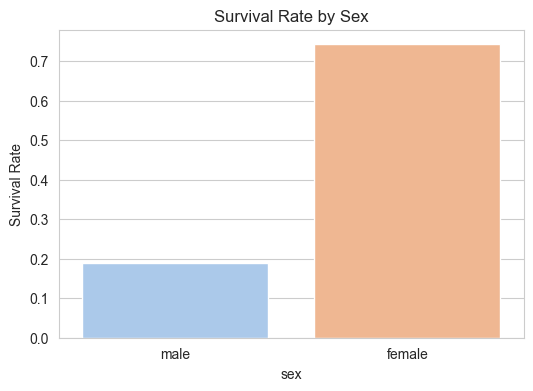

In [7]:
# 1. Survival by Sex
sex_group = df.groupby('sex')['survived'].agg(['count', 'mean']).round(2)
print(sex_group)

# Plot
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='sex', y='survived', hue='sex', errorbar=None, palette='pastel', legend=False)
plt.title('Survival Rate by Sex')
plt.ylabel('Survival Rate')
plt.show()


        count  mean
pclass             
1         216  0.63
2         184  0.47
3         491  0.24


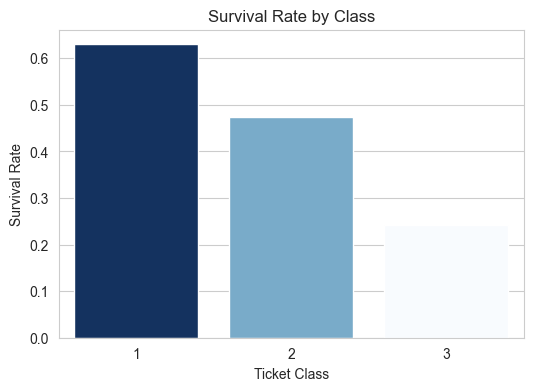

In [8]:
# 2. Survival by Ticket Class
class_group = df.groupby('pclass')['survived'].agg(['count', 'mean']).round(2)
print(class_group)

# Plot
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='pclass', y='survived', hue='pclass', errorbar=None, palette='Blues_r', legend=False)
plt.title('Survival Rate by Class')
plt.ylabel('Survival Rate')
plt.xlabel('Ticket Class')
plt.show()


             count  mean
age_band                
Child           69  0.58
Teen            70  0.43
Adult          602  0.36
Middle-aged    128  0.39
Senior          22  0.23


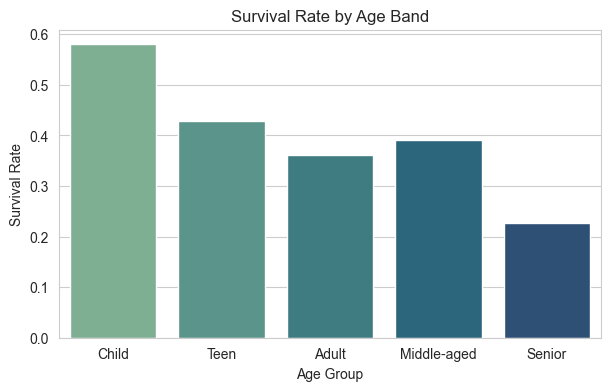

In [9]:
# 3. Survival by Age Band
df['age_band'] = pd.cut(df['age'], [0, 12, 18, 40, 60, 100],
                        labels=['Child', 'Teen', 'Adult', 'Middle-aged', 'Senior'])

age_group = df.groupby('age_band', observed=True)['survived'].agg(['count', 'mean']).round(2)
print(age_group)

# Plot
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x='age_band', y='survived', hue='age_band', errorbar=None, palette='crest', legend=False)
plt.title('Survival Rate by Age Band')
plt.ylabel('Survival Rate')
plt.xlabel('Age Group')
plt.show()


### Hidden Patterns Uncovered

#### Pattern 1: Class and Sex Combined (The Steerage Penalty)
Did women in 3rd class get the same chance of survival as women in 1st class?


               count  mean
pclass sex                
1      female     94  0.97
       male      122  0.37
2      female     76  0.92
       male      108  0.16
3      female    144  0.50
       male      347  0.14


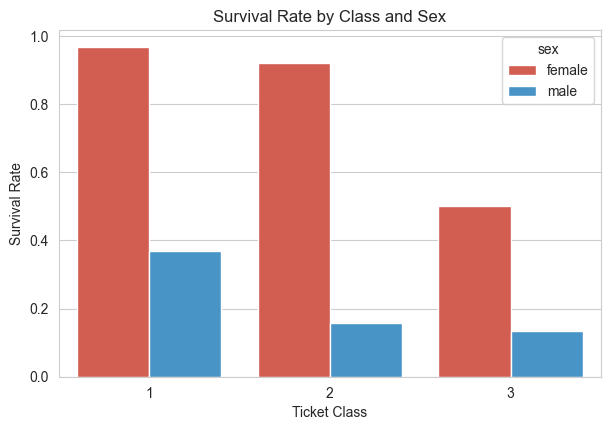

In [10]:
# Survival by both Class and Sex
class_sex = df.groupby(['pclass', 'sex'])['survived'].agg(['count', 'mean']).round(2)
print(class_sex)

plt.figure(figsize=(7, 4.5))
sns.barplot(data=df, x='pclass', y='survived', hue='sex', errorbar=None, palette=['#e74c3c', '#3498db'])
plt.title('Survival Rate by Class and Sex')
plt.ylabel('Survival Rate')
plt.xlabel('Ticket Class')
plt.show()


**Finding:** In 1st and 2nd class, over 90% of women survived (97% in 1st, 92% in 2nd). But in 3rd class, only **50%** of women survived. Ticket class played a massive role even for female passengers.


#### Pattern 2: Family Size and Traveling Alone
Did traveling alone help or hurt? We create `family_size = sibsp + parch + 1`.


--- Survival by Alone Status ---
       count  mean
alone             
False    354  0.51
True     537  0.30

--- Survival by Family Type ---
                    count  mean
family_type                    
Solo (1)              537  0.30
Small Family (2-4)    292  0.58
Large Family (5+)      62  0.16


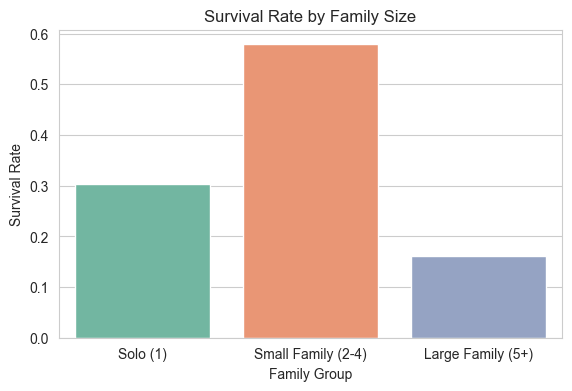

In [11]:
# Create family size
df['family_size'] = df['sibsp'] + df['parch'] + 1

# Compare solo vs family
print("--- Survival by Alone Status ---")
print(df.groupby('alone')['survived'].agg(['count', 'mean']).round(2))

# Segment into Small (2-4) vs Large (5+) families
df['family_type'] = pd.cut(df['family_size'], bins=[0, 1, 4, 15], labels=['Solo (1)', 'Small Family (2-4)', 'Large Family (5+)'])
print("\n--- Survival by Family Type ---")
print(df.groupby('family_type', observed=True)['survived'].agg(['count', 'mean']).round(2))

plt.figure(figsize=(6.5, 4))
sns.barplot(data=df, x='family_type', y='survived', hue='family_type', errorbar=None, palette='Set2', legend=False)
plt.title('Survival Rate by Family Size')
plt.ylabel('Survival Rate')
plt.xlabel('Family Group')
plt.show()


**Finding:** People in small families (2 to 4 members) had the best survival rate at **58%**. Solo travelers survived at only **30%**, and large families (5 or more) had the worst survival rate at **15%** because gathering a large family in chaotic steerage was difficult.


## Step 7: Answers to the Research Questions
Here are the clear answers to each question with exact numbers:

1. **Did women survive more than men?**  
   Yes, women survived at about **74%** (233 out of 314) compared to about **19%** (109 out of 577) for men.

2. **Did ticket class matter for survival?**  
   Yes, 1st class passengers had a **63%** survival rate, 2nd class had **47%**, while 3rd class had only **24%**.

3. **Was age related to survival?**  
   Yes, children (ages 0 to 12) had the highest survival rate at **58%**, while seniors (ages 60+) had the lowest survival rate at **23%**.

4. **Did ticket class impact female survival?**  
   Yes, 1st and 2nd class women had over **92%** survival, but 3rd class women had only a **50%** survival rate.

5. **Did family size make a difference?**  
   Yes, passengers with small families (2–4 people) had the highest survival rate at **58%**, while solo travelers had **30%** and large families (5+) dropped to **15%**.


## Step 8: Summary of Findings
- **Gender was the strongest survival factor:** The "women and children first" guideline resulted in women surviving almost 4 times more often than men.
- **Class privilege was huge:** Being in 1st class gave more than 2.5 times the survival chance compared to 3rd class.
- **Steerage penalty:** Even for women and children, being in 3rd class drastically lowered survival rates (half of 3rd class women and more than half of 3rd class children died).
- **Small families fared best:** Having 1 to 3 relatives provided mutual support during evacuation, whereas large families suffered due to evacuation bottlenecks.
